# Deep Learning Systems: Traffic Sign Recognition with a CNN

**Task type:** image classification using a Convolutional Neural Network (CNN), implemented in
PyTorch.

**Dataset:** [GTSRB (German Traffic Sign Recognition Benchmark)](https://benchmark.ini.rub.de/gtsrb_dataset.html)
(Stallkamp, Schlipsing, Salmen, & Igel, 2012), real photographs of German road signs across 43
classes, collected from real traffic to support traffic sign recognition research.  Downloaded from
[`tanganke/gtsrb`](https://huggingface.co/datasets/tanganke/gtsrb)

This notebook is Project 4 of a capstone series built around an ADAS / road-scene perception theme.
Projects 1-3 used tabular data; here, we move to raw-pixel image classification.


## 1. Setup

In [1]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from datasets import load_dataset
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

device = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print(f"Using device: {device}")

IMG_SIZE = 32
BATCH_SIZE = 128
EPOCHS = 10


Using device: mps


In [2]:
CLASS_NAMES = ['Speed limit (20km/h)', 'Speed limit (30km/h)', 'Speed limit (50km/h)', 'Speed limit (60km/h)', 'Speed limit (70km/h)', 'Speed limit (80km/h)', 'End of speed limit (80km/h)', 'Speed limit (100km/h)', 'Speed limit (120km/h)', 'No passing', 'No passing for vehicles over 3.5 metric tons', 'Right-of-way at the next intersection', 'Priority road', 'Yield', 'Stop', 'No vehicles', 'Vehicles over 3.5 metric tons prohibited', 'No entry', 'General caution', 'Dangerous curve to the left', 'Dangerous curve to the right', 'Double curve', 'Bumpy road', 'Slippery road', 'Road narrows on the right', 'Road work', 'Traffic signals', 'Pedestrians', 'Children crossing', 'Bicycles crossing', 'Beware of ice/snow', 'Wild animals crossing', 'End of all speed and passing limits', 'Turn right ahead', 'Turn left ahead', 'Ahead only', 'Go straight or right', 'Go straight or left', 'Keep right', 'Keep left', 'Roundabout mandatory', 'End of no passing', 'End of no passing by vehicles over 3.5 metric tons']
print(f"Number of classes: {len(CLASS_NAMES)}")


Number of classes: 43


## 2. Load and Inspect the Dataset

In [3]:
class HFImageDataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.hf_split = hf_split
        self.transform = transform

    def __len__(self):
        return len(self.hf_split)

    def __getitem__(self, idx):
        row = self.hf_split[idx]
        image = row["image"].convert("RGB")
        label = row["label"]
        if self.transform is not None:
            image = self.transform(image)
        return image, label


base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

hf_train = load_dataset("tanganke/gtsrb", split="train")
hf_test = load_dataset("tanganke/gtsrb", split="test")

train_full_base = HFImageDataset(hf_train, transform=base_transform)
test_set = HFImageDataset(hf_test, transform=base_transform)

print(f"Train split size: {len(train_full_base)}")
print(f"Test split size: {len(test_set)}")

sample_image, sample_label = train_full_base[0]
print(f"Sample tensor shape: {sample_image.shape}, dtype: {sample_image.dtype}")
print(f"Sample label: {sample_label} ({CLASS_NAMES[sample_label]})")


Train split size: 26640
Test split size: 12630
Sample tensor shape: torch.Size([3, 32, 32]), dtype: torch.float32
Sample label: 0 (Speed limit (20km/h))


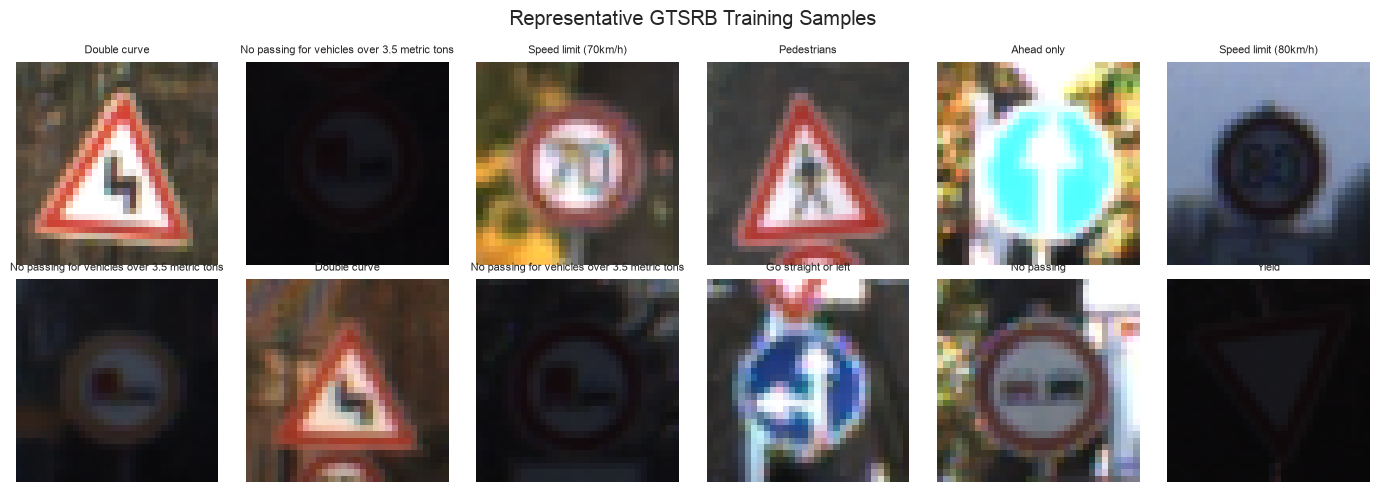

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(train_full_base), size=12, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    img, label = train_full_base[idx]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[label], fontsize=8)
    ax.axis("off")

plt.suptitle("Representative GTSRB Training Samples")
plt.tight_layout()
plt.savefig("figure1_sample_images.png", dpi=150)
plt.show()


**Data quality and preprocessing notes.** The raw photographs vary in resolution since they were extracted from real roadside video and include some
surrounding background (Stallkamp et al., 2012). All
images are resized to a fixed 32x32 resolution so they can be batched into fixed-size tensors.
Pixel values are scaled to [0, 1]. Class sizes are imbalanced: common signs such as
speed limits have thousands of training examples while rarer signs have only a few hundred.


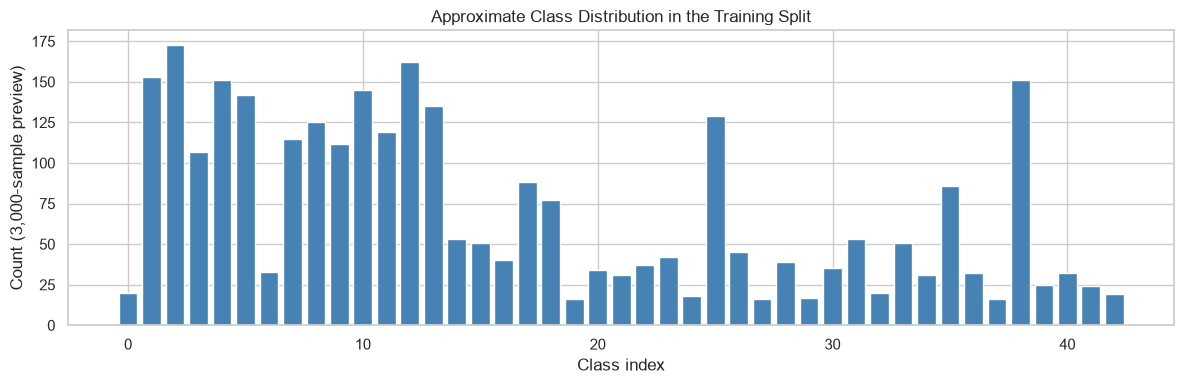

In [5]:
labels_preview = [train_full_base[i][1] for i in rng.choice(len(train_full_base), size=3000, replace=False)]
class_counts = pd.Series(labels_preview).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(class_counts.index, class_counts.values, color="steelblue")
ax.set_xlabel("Class index")
ax.set_ylabel("Count (3,000-sample preview)")
ax.set_title("Approximate Class Distribution in the Training Split")
plt.tight_layout()
plt.savefig("figure2_class_distribution.png", dpi=150)
plt.show()


## 3. Train/Validation Split

The published `train` split is further divided 85/15 into a training set and a validation set used
to monitor training progress. The same index split is reused for both the baseline and the
augmentation experiment below, and the validation and test sets are never augmented.


In [6]:
n_total = len(train_full_base)
indices = np.arange(n_total)
rng.shuffle(indices)
n_val = int(0.15 * n_total)
val_idx = indices[:n_val].tolist()
train_idx = indices[n_val:].tolist()
print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test (held out): {len(test_set)}")


Train: 22644 | Validation: 3996 | Test (held out): 12630


## 4. Baseline CNN

**Architecture.** Three convolution-ReLU-max pool blocks (3->32->64->128 channels) progressively
extract spatial features while halving the spatial resolution each time (32x32 -> 16x16 -> 8x8 ->
4x4), which is the standard convolutional feature-extraction pattern for small fixed-size images
(LeCun, Bottou, Bengio, & Haffner, 1998). The resulting 128x4x4 feature map is flattened into a
256-unit fully connected layer with a ReLU activation, then a final linear layer produces 43 raw
class scores (logits), one per sign class. ReLU is used throughout because it is computationally
cheap and avoids the vanishing-gradient problems of sigmoid/tanh activations in deeper stacks
(LeCun et al., 1998). No final softmax layer is needed in the model itself because
`nn.CrossEntropyLoss` applies it automatically.

**Training setup.** Adam is used as the optimizer (Kingma & Ba, 2015) with a learning rate of 1e-3,
and the loss function is cross-entropy, the standard choice for multi-class classification with
mutually exclusive labels. Both experiments below train for the same number of epochs with the same
batch size, so epoch count and batch size are held constant and are not part of the comparison.


In [7]:
class TrafficSignCNN(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def train_model(model, train_loader, val_loader, epochs, device, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1}/{epochs}  train_loss={train_loss:.4f}  "
              f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

    return history


In [8]:
val_ds = Subset(train_full_base, val_idx)
train_base_ds = Subset(train_full_base, train_idx)

train_base_loader = DataLoader(train_base_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

torch.manual_seed(RANDOM_STATE)
baseline_model = TrafficSignCNN(num_classes=len(CLASS_NAMES))
baseline_history = train_model(baseline_model, train_base_loader, val_loader, EPOCHS, device)


Epoch 1/10  train_loss=2.6872  val_loss=1.6481  val_acc=0.4547


Epoch 2/10  train_loss=1.0799  val_loss=0.6900  val_acc=0.7718


Epoch 3/10  train_loss=0.4649  val_loss=0.3234  val_acc=0.9052


Epoch 4/10  train_loss=0.2223  val_loss=0.1937  val_acc=0.9404


Epoch 5/10  train_loss=0.1193  val_loss=0.1538  val_acc=0.9560


Epoch 6/10  train_loss=0.0688  val_loss=0.1290  val_acc=0.9640


Epoch 7/10  train_loss=0.0472  val_loss=0.0843  val_acc=0.9780


Epoch 8/10  train_loss=0.0360  val_loss=0.1097  val_acc=0.9752


Epoch 9/10  train_loss=0.0342  val_loss=0.0887  val_acc=0.9775


Epoch 10/10  train_loss=0.0250  val_loss=0.0716  val_acc=0.9835


## 5. Controlled Comparison: Adding Data Augmentation

**What changed:** the training images for this second run pass through random rotation (+/-15
degrees), random translation/scaling (+/-10%), and random brightness/contrast jitter before being
converted to tensors. Validation and test images are **not** augmented in either run.

**Why this change:** road signs in the wild are photographed from varying distances, angles, and
lighting conditions. Data augmentation is a standard regularization strategy that exposes the model
to these variations synthetically, which can reduce overfitting to the exact pixel arrangements seen
during training and improve generalization to the held-out test set (Shorten & Khoshgoftaar, 2019).

**How it differs from the baseline:** the architecture (`TrafficSignCNN`), number
of epochs, batch size, optimizer, learning rate, loss function, random seed for weight
initialization, and the train/validation/test split indices are all identical. The only
difference is the augmentation transform applied to the training images.


In [9]:
aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

train_full_aug = HFImageDataset(hf_train, transform=aug_transform)
train_aug_ds = Subset(train_full_aug, train_idx)
train_aug_loader = DataLoader(train_aug_ds, batch_size=BATCH_SIZE, shuffle=True)

torch.manual_seed(RANDOM_STATE)
augmented_model = TrafficSignCNN(num_classes=len(CLASS_NAMES))
augmented_history = train_model(augmented_model, train_aug_loader, val_loader, EPOCHS, device)


Epoch 1/10  train_loss=3.0061  val_loss=2.0807  val_acc=0.3368


Epoch 2/10  train_loss=1.8007  val_loss=1.2482  val_acc=0.5951


Epoch 3/10  train_loss=1.2377  val_loss=0.8117  val_acc=0.7315


Epoch 4/10  train_loss=0.8490  val_loss=0.4947  val_acc=0.8303


Epoch 5/10  train_loss=0.5982  val_loss=0.3304  val_acc=0.8939


Epoch 6/10  train_loss=0.4674  val_loss=0.2765  val_acc=0.9062


Epoch 7/10  train_loss=0.3580  val_loss=0.2434  val_acc=0.9197


Epoch 8/10  train_loss=0.2963  val_loss=0.1166  val_acc=0.9647


Epoch 9/10  train_loss=0.2412  val_loss=0.1001  val_acc=0.9685


Epoch 10/10  train_loss=0.2004  val_loss=0.0771  val_acc=0.9770


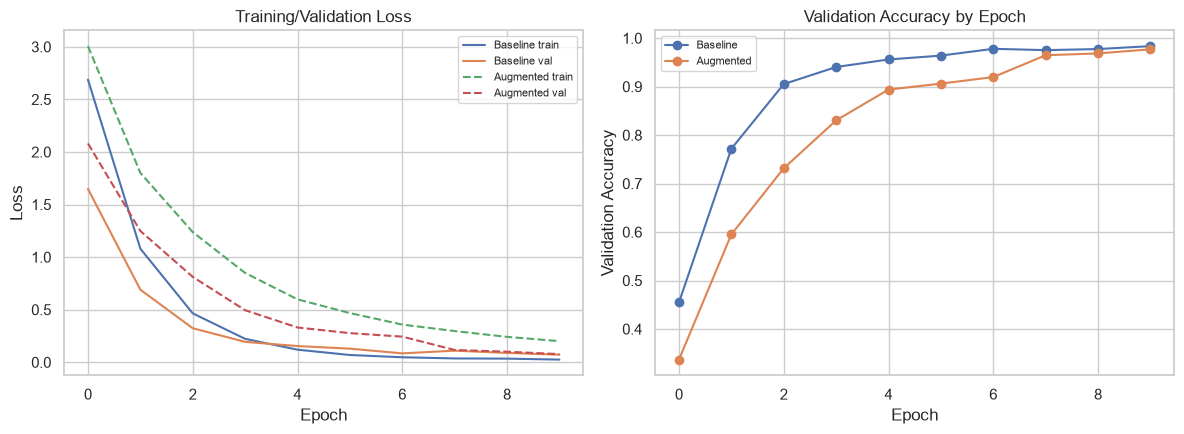

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(baseline_history["train_loss"], label="Baseline train")
axes[0].plot(baseline_history["val_loss"], label="Baseline val")
axes[0].plot(augmented_history["train_loss"], label="Augmented train", linestyle="--")
axes[0].plot(augmented_history["val_loss"], label="Augmented val", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training/Validation Loss")
axes[0].legend(fontsize=8)

axes[1].plot(baseline_history["val_acc"], label="Baseline", marker="o")
axes[1].plot(augmented_history["val_acc"], label="Augmented", marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy")
axes[1].set_title("Validation Accuracy by Epoch")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("figure3_training_curves.png", dpi=150)
plt.show()


## 6. Evaluation and Comparison on the Held-Out Test Set

Both models are evaluated once, on the same never-touched test split, using accuracy and macro-F1
(an unweighted average across all 43 classes, which keeps rare sign classes from being drowned out by
common ones such as speed limits).


In [11]:
def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            all_preds.append(outputs.argmax(1).cpu())
            all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()


baseline_preds, test_labels = evaluate(baseline_model, test_loader, device)
augmented_preds, _ = evaluate(augmented_model, test_loader, device)

baseline_acc = accuracy_score(test_labels, baseline_preds)
augmented_acc = accuracy_score(test_labels, augmented_preds)
baseline_f1 = f1_score(test_labels, baseline_preds, average="macro")
augmented_f1 = f1_score(test_labels, augmented_preds, average="macro")

comparison = pd.DataFrame({
    "Model": ["Baseline", "Baseline + Augmentation"],
    "Test Accuracy": [baseline_acc, augmented_acc],
    "Macro F1": [baseline_f1, augmented_f1],
})
comparison


,Model,Test Accuracy,Macro F1
0,Baseline,0.819557,0.751188
1,Baseline + Augmentation,0.811085,0.752307


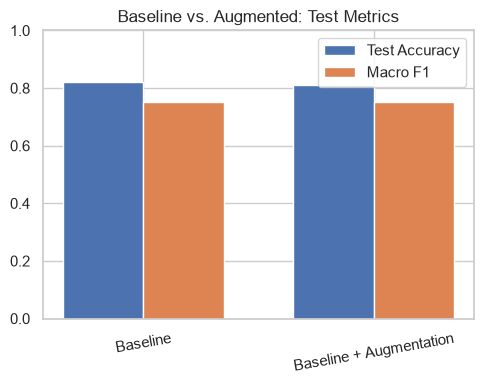

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, comparison["Test Accuracy"], width, label="Test Accuracy")
ax.bar(x + width/2, comparison["Macro F1"], width, label="Macro F1")
ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=10)
ax.set_ylim(0, 1)
ax.set_title("Baseline vs. Augmented: Test Metrics")
ax.legend()
plt.tight_layout()
plt.savefig("figure4_test_metric_comparison.png", dpi=150)
plt.show()


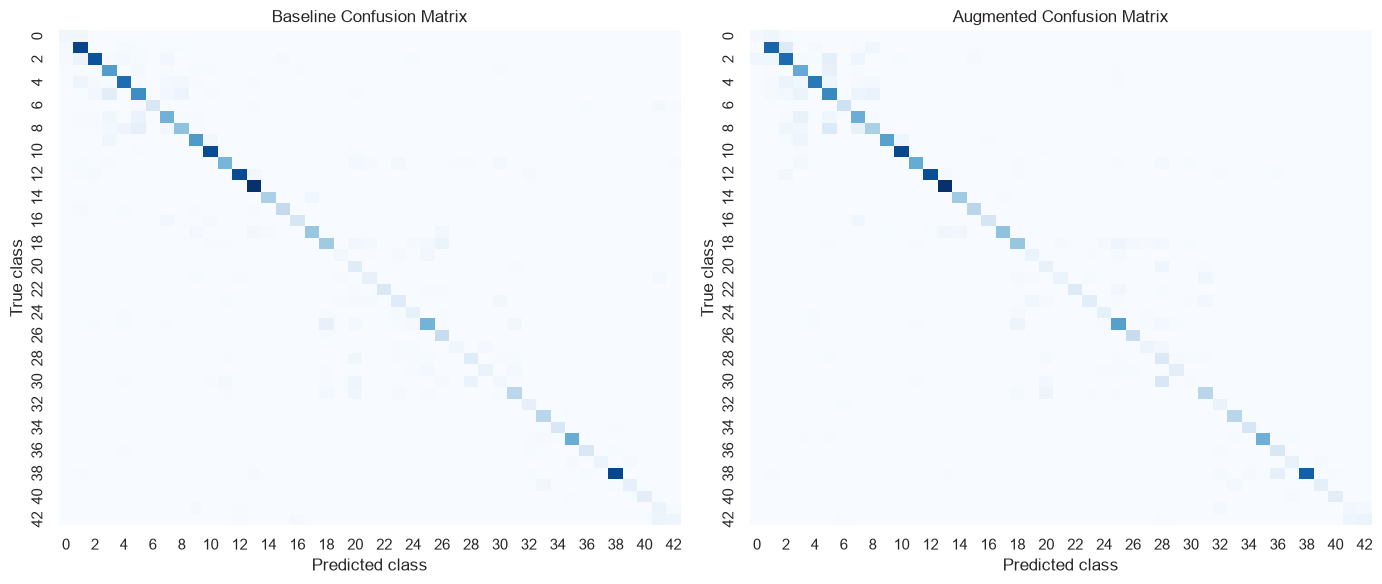

In [13]:
cm_baseline = confusion_matrix(test_labels, baseline_preds)
cm_augmented = confusion_matrix(test_labels, augmented_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(cm_baseline, cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Baseline Confusion Matrix")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("True class")

sns.heatmap(cm_augmented, cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Augmented Confusion Matrix")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")

plt.tight_layout()
plt.savefig("figure5_confusion_matrices.png", dpi=150)
plt.show()


### A specific example

here, we look for a test image the baseline model misclassifies but the augmented model
classifies correctly, to ground the comparison in one concrete case.


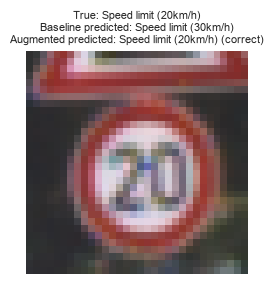

Test index 26: baseline wrong, augmented correct.


In [14]:
fixed_only_by_aug = np.where((baseline_preds != test_labels) & (augmented_preds == test_labels))[0]

if len(fixed_only_by_aug) > 0:
    example_idx = int(fixed_only_by_aug[0])
    img, true_label = test_set[example_idx]

    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(img.permute(1, 2, 0))
    ax.axis("off")
    ax.set_title(
        f"True: {CLASS_NAMES[true_label]}\n"
        f"Baseline predicted: {CLASS_NAMES[baseline_preds[example_idx]]}\n"
        f"Augmented predicted: {CLASS_NAMES[augmented_preds[example_idx]]} (correct)",
        fontsize=8,
    )
    plt.tight_layout()
    plt.savefig("figure6_behavior_example.png", dpi=150)
    plt.show()
    print(f"Test index {example_idx}: baseline wrong, augmented correct.")
else:
    print("No case found where augmentation alone fixed a baseline error in this run.")


## 7. Notebook Summary

This notebook trained a CNN to classify German traffic signs (GTSRB, 43 classes) from raw pixels,
using 22,644 training images, a 3,996-image validation split, and the official 12,630-image test
split held out until final evaluation. The baseline CNN reached 98.4% validation accuracy but only
81.96% test accuracy (macro-F1 0.751). the augmented model, identical in except that training images were randomly rotated, shifted, and brightness-jittered, trained more slowly and
ended at 97.7% validation accuracy and 81.11% test accuracy (macro-F1 0.752). The most informative result was not the augmentation
comparison itself but the large gap between validation and test accuracy for both models, which
points to GTSRB's known structure of near-duplicate image tracks inflating validation performance
relative to truly unseen sign instances. A concrete case of this kind of error is shown directly in
Section 6: the baseline misclassified a 20 km/h speed limit sign as 30 km/h, a mistake the augmented
model corrected, which matches the known visual similarity between adjacent speed-limit signs.